
Dataset Preview:
         Date  Day_of_Week  Is_Exam  Is_Rainy  Prev_Day_Orders  Demand_Label
0  2025-01-01            2        0         0               40             0
1  2025-01-02            3        0         0               36             0
2  2025-01-03            4        1         0               40             1
3  2025-01-04            5        1         0               51             1
4  2025-01-05            6        0         0               67             1

Model Accuracy: 95.83%

Confusion Matrix:
[[ 0  1]
 [ 0 23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.96      1.00      0.98        23

    accuracy                           0.96        24
   macro avg       0.48      0.50      0.49        24
weighted avg       0.92      0.96      0.94        24



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


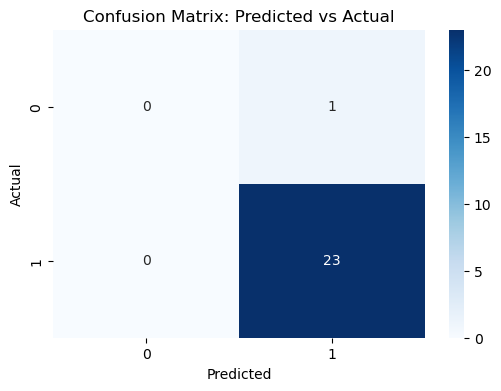

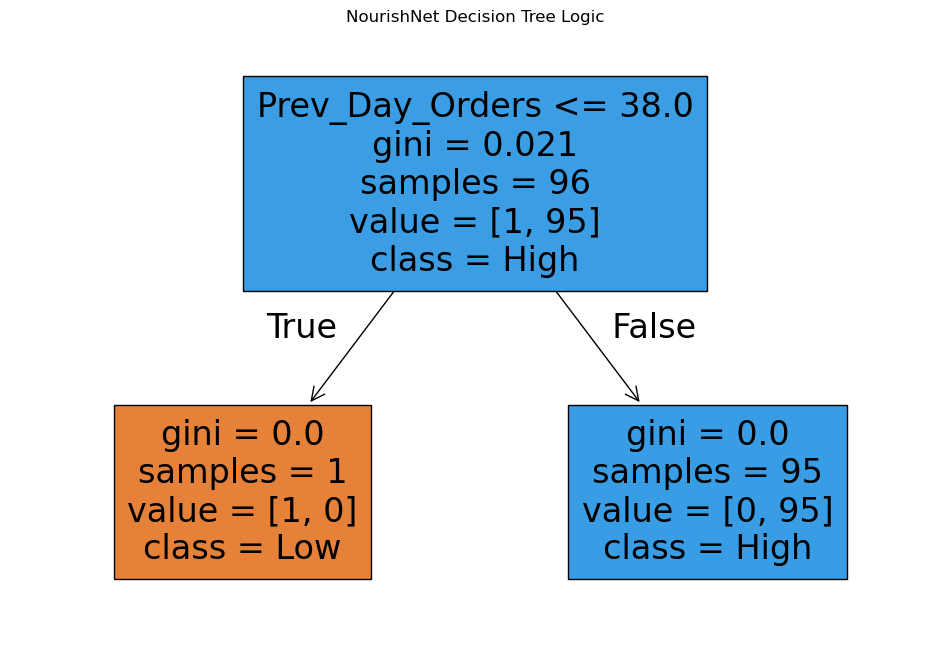

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- STEP 1: LOAD DATASET FROM CSV FILE ---

df = pd.read_csv("Downloads/tiffin_demand_dataset.csv")

print("\nDataset Preview:")
print(df.head())

# --- STEP 2: PREPARE FEATURES AND TARGET ---

# Remove Date column because ML models cannot process strings
X = df.drop(['Demand_Label', 'Date'], axis=1)

y = df['Demand_Label']

# --- STEP 3: TRAIN-TEST SPLIT ---

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- STEP 4: MODEL TRAINING ---

model = DecisionTreeClassifier(max_depth=3)
model.fit(X_train, y_train)

# --- STEP 5: PREDICTIONS ---

y_pred = model.predict(X_test)

# --- STEP 6: MODEL EVALUATION ---

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"\nModel Accuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# --- STEP 7: VISUALIZATION ---

plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix: Predicted vs Actual")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

plt.figure(figsize=(12,8))
plot_tree(model, feature_names=X.columns, class_names=['Low', 'High'], filled=True)
plt.title("NourishNet Decision Tree Logic")
plt.show()
